# Лабораторная работа № 3 — Декомпозиция временного ряда

**Цель:** сравнить классическую декомпозицию, STL и MSTL на ряду с суточной и недельной сезонностью.  
**Данные:** почасовая мощность за 2007 год из [UCI Individual Household Electric Power Consumption](https://archive.ics.uci.edu/dataset/235/individual+household+electric+power+consumption) — тот же датасет, что и в лаб_02.

## 1. Загрузка данных

Для декомпозиции заполним пропуски линейной интерполяцией. Длинные разрывы могут влиять на оценки компонент.

In [23]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import seasonal_decompose, STL, MSTL
from statsmodels.tsa.stattools import acf

url = (
    "https://archive.ics.uci.edu/static/public/235/"
    "individual+household+electric+power+consumption.zip"
)
df = pd.read_csv(
    url, compression="zip", sep=";",
    usecols=["Date", "Time", "Global_active_power"], na_values=["?"],
)
df["timestamp"] = pd.to_datetime(df["Date"] + " " + df["Time"], format="%d/%m/%Y %H:%M:%S")
df["Global_active_power"] = pd.to_numeric(df["Global_active_power"], errors="coerce")

series = (df.sort_values("timestamp").drop_duplicates("timestamp")
            .set_index("timestamp")["Global_active_power"]
            .loc["2007"].resample("h").mean().asfreq("h"))
missing = int(series.isna().sum())
series = series.interpolate(method="time", limit_direction="both")

print(f"2007 год: {len(series)} часов; заполнено пропусков: {missing}")

2007 год: 8760 часов; заполнено пропусков: 62


## 2. Визуальный анализ

Посмотрим на ряд, суточный и недельный профили, а также тепловую карту. Для сравнения методов используем **аддитивную модель** $Y=T+S+R$: сезонные эффекты рассматриваем как отклонения мощности в кВт. Проверим по графикам, насколько стабилен их размах.

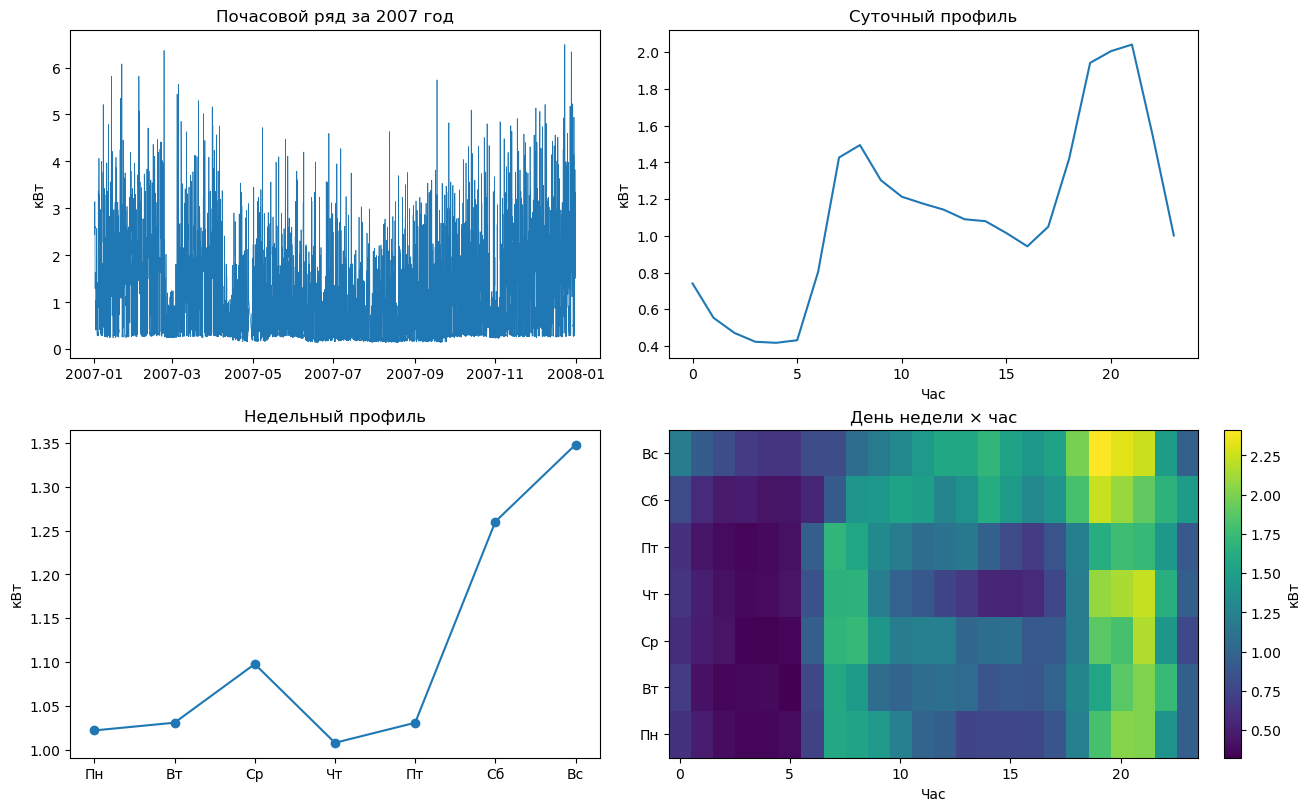

In [16]:
hourly = series.groupby(series.index.hour).mean()
weekly = series.groupby(series.index.dayofweek).mean()
heatmap = series.groupby([series.index.dayofweek, series.index.hour]).mean().unstack()
days = ["Пн", "Вт", "Ср", "Чт", "Пт", "Сб", "Вс"]

fig, ax = plt.subplots(2, 2, figsize=(13, 8), constrained_layout=True)
ax[0, 0].plot(series, lw=0.5)
ax[0, 0].set(title="Почасовой ряд за 2007 год", ylabel="кВт")
ax[0, 1].plot(hourly.index, hourly.values)
ax[0, 1].set(title="Суточный профиль", xlabel="Час", ylabel="кВт")
ax[1, 0].plot(weekly.index, weekly.values, marker="o")
ax[1, 0].set(title="Недельный профиль", xticks=range(7), xticklabels=days, ylabel="кВт")
im = ax[1, 1].imshow(heatmap, aspect="auto", origin="lower", cmap="viridis")
ax[1, 1].set(title="День недели × час", xlabel="Час", yticks=range(7), yticklabels=days)
fig.colorbar(im, ax=ax[1, 1], label="кВт")
plt.show()

## 3. Автокорреляция

Проверяем суточный и недельный циклы на лагах 24 и 168 часов.

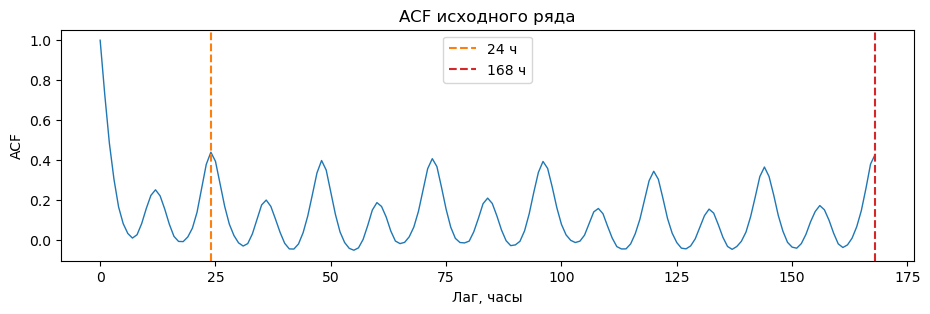

ACF(24) = 0.439; ACF(168) = 0.428


In [17]:
acf_original = acf(series, nlags=168, fft=True)
plt.figure(figsize=(11, 3))
plt.plot(acf_original, lw=1)
plt.axvline(24, color="tab:orange", ls="--", label="24 ч")
plt.axvline(168, color="tab:red", ls="--", label="168 ч")
plt.title("ACF исходного ряда")
plt.xlabel("Лаг, часы")
plt.ylabel("ACF")
plt.legend()
plt.show()

print(f"ACF(24) = {acf_original[24]:.3f}; ACF(168) = {acf_original[168]:.3f}")

## 4. Классическая декомпозиция

`period=24`: выделяем суточную сезонность. Недельная может остаться в остатках.

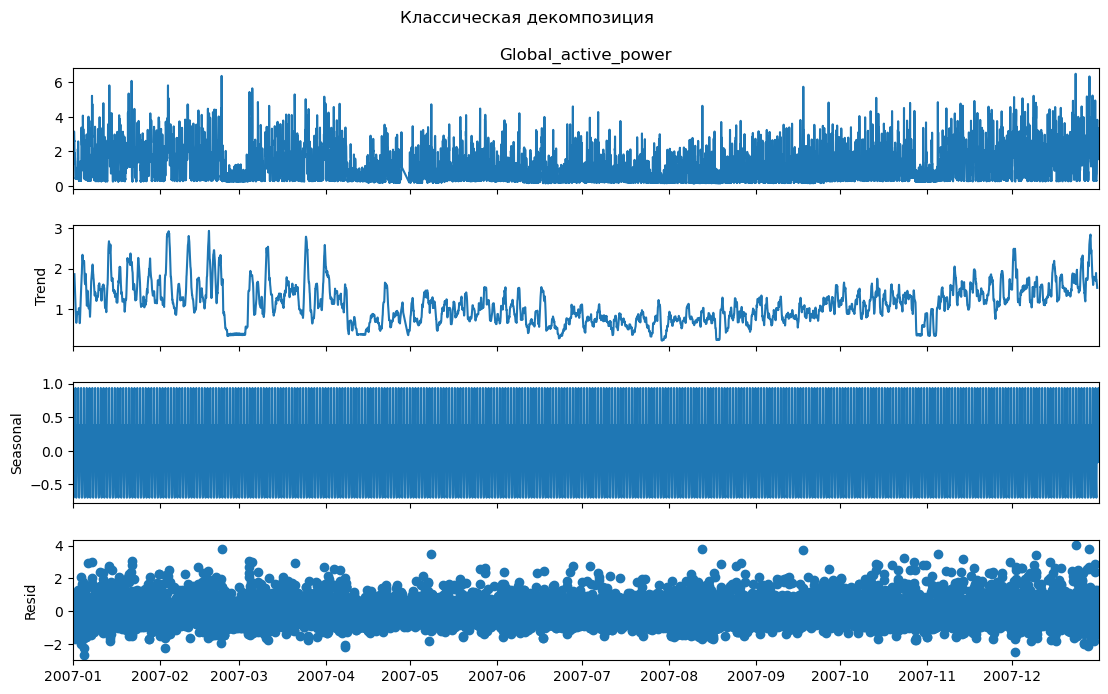

In [18]:
classic = seasonal_decompose(series, model="additive", period=24)
fig = classic.plot()
fig.set_size_inches(12, 7)
fig.suptitle("Классическая декомпозиция", y=1.01)
plt.show()

## 5. STL

`period=24`, `robust=True`. Параметр `seasonal=13` задаёт сглаживание сезонного профиля, `trend=337` — более плавный тренд (около двух недель). Оба окна нечётные.

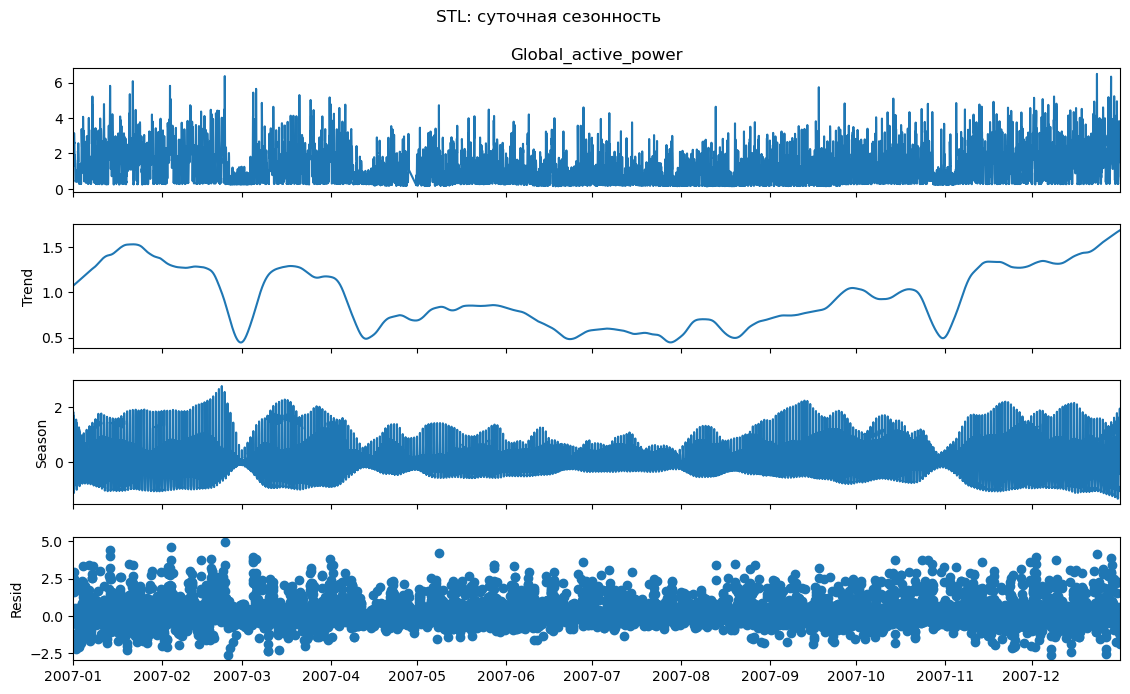

In [19]:
stl = STL(series, period=24, seasonal=13, trend=337, robust=True).fit()
fig = stl.plot()
fig.set_size_inches(12, 7)
fig.suptitle("STL: суточная сезонность", y=1.01)
plt.show()

## 6. MSTL

Выделяем суточную (24 часа) и недельную (168 часов) сезонность одновременно.

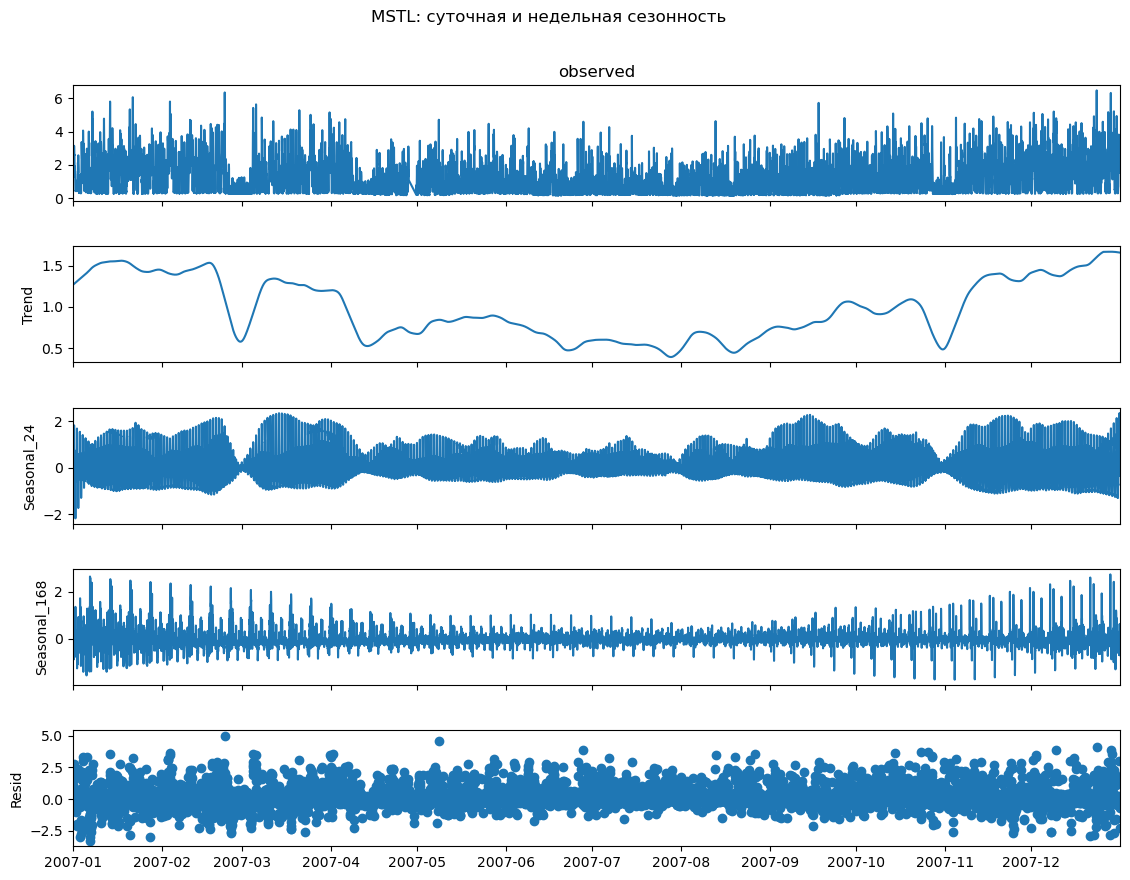

In [20]:
mstl = MSTL(series, periods=(24, 168), stl_kwargs={"robust": True}).fit()
fig = mstl.plot()
fig.set_size_inches(12, 9)
fig.suptitle("MSTL: суточная и недельная сезонность", y=1.01)
plt.show()

## 7. Сравнение остатков

Сравним дисперсии и остаточную автокорреляцию на лагах 24 и 168. Для честного сравнения используем общие даты (без краёв, потерянных классическим методом).

              Дисперсия остатка  ACF(24)  ACF(168)
Классическая              0.517    0.161     0.180
STL                       0.564    0.026     0.162
MSTL                      0.486    0.013     0.038


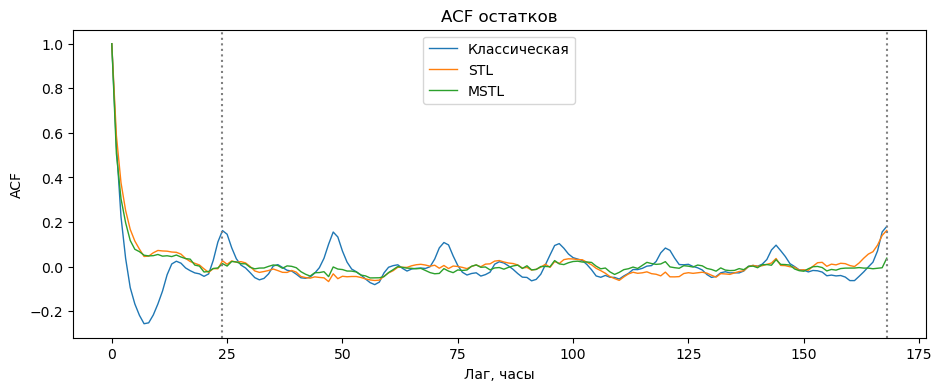

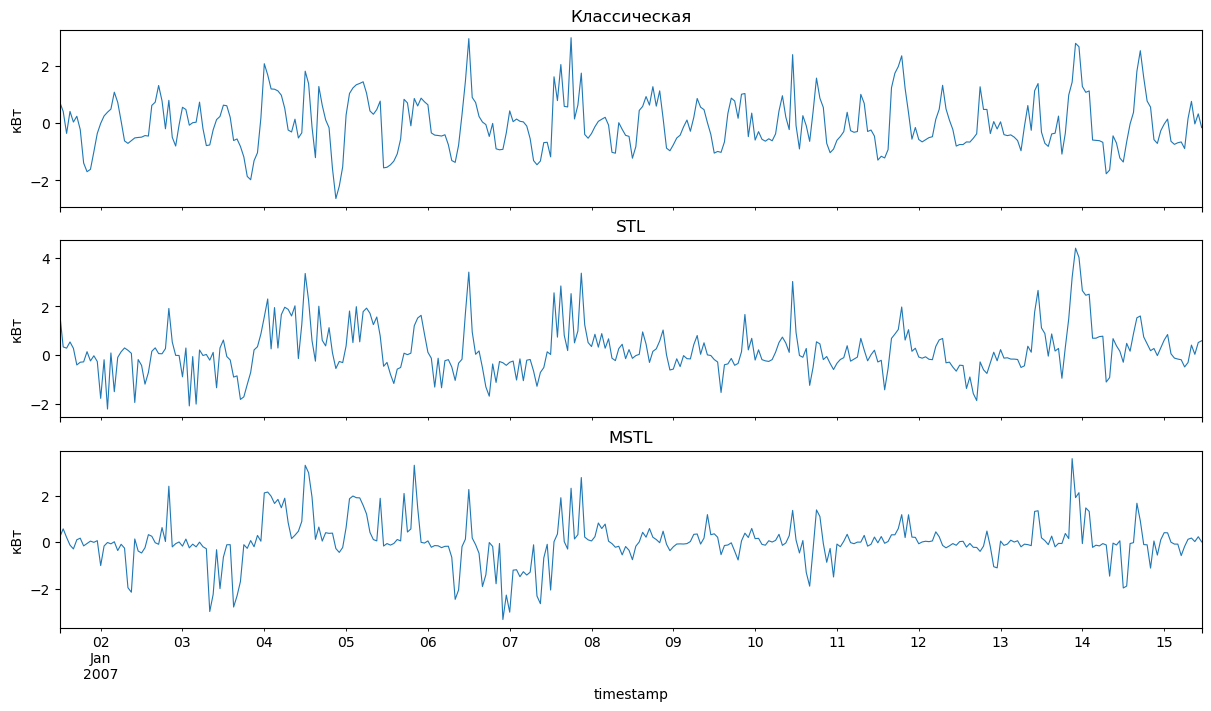

In [21]:
valid = classic.resid.dropna().index
residuals = {
    "Классическая": classic.resid.loc[valid],
    "STL": stl.resid.loc[valid],
    "MSTL": mstl.resid.loc[valid],
}

acf_residuals = {name: acf(r, nlags=168, fft=True) for name, r in residuals.items()}
comparison = pd.DataFrame({
    name: {
        "Дисперсия остатка": r.var(ddof=0),
        "ACF(24)": acf_residuals[name][24],
        "ACF(168)": acf_residuals[name][168],
    }
    for name, r in residuals.items()
}).T
print(comparison.round(3).to_string())

plt.figure(figsize=(11, 4))
for name, values in acf_residuals.items():
    plt.plot(values, label=name, lw=1)
plt.axvline(24, color="gray", ls=":")
plt.axvline(168, color="gray", ls=":")
plt.title("ACF остатков")
plt.xlabel("Лаг, часы")
plt.ylabel("ACF")
plt.legend()
plt.show()

fig, axes = plt.subplots(3, 1, figsize=(12, 7), sharex=True, constrained_layout=True)
for ax, (name, r) in zip(axes, residuals.items()):
    r.iloc[:24 * 14].plot(ax=ax, lw=0.8, title=name)
    ax.set_ylabel("кВт")
plt.show()

### Выводы

1. Исходный временной ряд демонстрирует суточную и недельную сезонность, что подтверждается значениями ACF на лагах 24 (0.439) и 168 (0.428).

2. Классическая декомпозиция выделяет суточную сезонность, однако в остатках сохраняется выраженная периодическая структура.

3. STL лучше устраняет суточную автокорреляцию, но не учитывает недельную сезонность. Дисперсия его остатка составляет 0.564.

4. MSTL показал лучшие результаты: дисперсия остатка снизилась до 0.486, а ACF на лагах 24 и 168 — до 0.013 и 0.038 соответственно.

5. Для данного ряда предпочтительнее MSTL, поскольку он позволяет одновременно выделить суточную и недельную сезонности. При этом остатки всё ещё содержат некоторую краткосрочную зависимость.